In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid")

# Load User Reviews dataset
df_reviews = pd.read_csv('User_Reviews_Cleaned.csv')
print("User Reviews Dataset Shape:", df_reviews.shape)
df_reviews.head()

User Reviews Dataset Shape: (29692, 5)


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
3,10 Best Foods for You,Best idea us,Positive,1.00,0.300000
4,10 Best Foods for You,Best way,Positive,1.00,0.300000


In [2]:
# Check missing values before cleaning
print("Missing values per column:\n", df_reviews.isnull().sum())

# Drop rows where Sentiment or Translated_Review is missing
df_reviews.dropna(subset=['Sentiment', 'Sentiment_Polarity'], inplace=True)

print("\nCleaned User Reviews Shape:", df_reviews.shape)

Missing values per column:
 App                       0
Translated_Review         0
Sentiment                 0
Sentiment_Polarity        0
Sentiment_Subjectivity    0
dtype: int64

Cleaned User Reviews Shape: (29692, 5)


In [3]:
# Technical statistical summary of sentiment metrics
sentiment_stats = pd.DataFrame({
    'Mean': df_reviews[['Sentiment_Polarity', 'Sentiment_Subjectivity']].mean(),
    'Median': df_reviews[['Sentiment_Polarity', 'Sentiment_Subjectivity']].median(),
    'Std Dev': df_reviews[['Sentiment_Polarity', 'Sentiment_Subjectivity']].std(),
    'Skewness': df_reviews[['Sentiment_Polarity', 'Sentiment_Subjectivity']].skew()
})

print("=== Sentiment Polarity & Subjectivity Statistics ===")
print(sentiment_stats.round(3))

=== Sentiment Polarity & Subjectivity Statistics ===
                         Mean  Median  Std Dev  Skewness
Sentiment_Polarity      0.189   0.157    0.356    -0.123
Sentiment_Subjectivity  0.491   0.514    0.266    -0.297


=== Sentiment Category Breakdown ===
           Count  Percentage (%)
Sentiment                       
Positive   19015           64.04
Negative    6321           21.29
Neutral     4356           14.67


C:\Users\Tarun Das\AppData\Local\Temp\ipykernel_6000\2501154328.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_reviews, x='Sentiment', order=['Positive', 'Neutral', 'Negative'], palette='Set2')


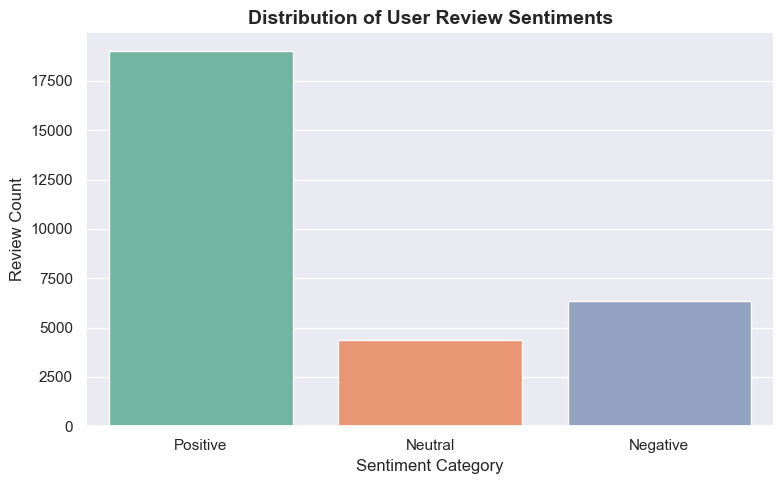

In [4]:
# Calculate sentiment distribution counts and percentages
sentiment_counts = df_reviews['Sentiment'].value_counts()
sentiment_percentages = df_reviews['Sentiment'].value_counts(normalize=True) * 100

sentiment_summary_df = pd.DataFrame({
    'Count': sentiment_counts,
    'Percentage (%)': sentiment_percentages.round(2)
})

print("=== Sentiment Category Breakdown ===")
print(sentiment_summary_df)

# Visualize Sentiment Distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df_reviews, x='Sentiment', order=['Positive', 'Neutral', 'Negative'], palette='Set2')
plt.title('Distribution of User Review Sentiments', fontsize=14, fontweight='bold')
plt.xlabel('Sentiment Category', fontsize=12)
plt.ylabel('Review Count', fontsize=12)
plt.tight_layout()
plt.show()

In [5]:
# Aggregate sentiment polarity by application
app_sentiment_agg = df_reviews.groupby('App').agg(
    Total_Reviews=('Translated_Review', 'count'),
    Mean_Polarity=('Sentiment_Polarity', 'mean'),
    Mean_Subjectivity=('Sentiment_Subjectivity', 'mean')
).reset_index()

# Filter apps with significant review volume (e.g., > 10 reviews)
active_apps_sentiment = app_sentiment_agg[app_sentiment_agg['Total_Reviews'] >= 10]
active_apps_sentiment = active_apps_sentiment.sort_values(by='Mean_Polarity', ascending=False)

print("=== Top 10 Apps by Highest User Sentiment Polarity ===")
display(active_apps_sentiment.head(10).round(3))

=== Top 10 Apps by Highest User Sentiment Polarity ===


,App,Total_Reviews,Mean_Polarity,Mean_Subjectivity
393,Cookbook Recipes,37,0.565,0.643
734,Goldstar: Live Event Tickets,40,0.549,0.635
23,850 Sports News Digest,39,0.543,0.692
289,C++ Tutorials,36,0.531,0.567
836,Hipmunk Hotels & Flights,33,0.531,0.614
812,Haystack TV: Local & World News - Free,15,0.530,0.552
86,"All Football GO- Live Score, Games",36,0.527,0.514
262,Brasileirão Pro 2018 - Série A e B,36,0.514,0.519
156,BBVA Spain,32,0.506,0.590
544,"Eve Period Tracker - Love, Sex & Relationships...",26,0.505,0.502


In [6]:
import pandas as pd
import numpy as np

# Load user reviews dataset
df_reviews = pd.read_csv('User_Reviews_Cleaned.csv')

# Drop nulls in sentiment columns
df_reviews.dropna(subset=['Sentiment_Polarity', 'Sentiment_Subjectivity'], inplace=True)

# Compute advanced distribution metrics
distribution_metrics = pd.DataFrame({
    'Mean': df_reviews[['Sentiment_Polarity', 'Sentiment_Subjectivity']].mean(),
    'Median': df_reviews[['Sentiment_Polarity', 'Sentiment_Subjectivity']].median(),
    'Std Dev': df_reviews[['Sentiment_Polarity', 'Sentiment_Subjectivity']].std(),
    'Skewness': df_reviews[['Sentiment_Polarity', 'Sentiment_Subjectivity']].skew(),
    'Kurtosis': df_reviews[['Sentiment_Polarity', 'Sentiment_Subjectivity']].kurtosis()
})

print("=== Advanced Distribution Metrics for Sentiment Scores ===")
print(distribution_metrics.round(3))

=== Advanced Distribution Metrics for Sentiment Scores ===
                         Mean  Median  Std Dev  Skewness  Kurtosis
Sentiment_Polarity      0.189   0.157    0.356    -0.123     0.602
Sentiment_Subjectivity  0.491   0.514    0.266    -0.297    -0.383


In [7]:
# Segment reviews into Subjectivity Categories
# Subjectivity ranges from 0 (objective/factual) to 1 (subjective/opinionated)
df_reviews['Subjectivity_Tier'] = pd.cut(
    df_reviews['Sentiment_Subjectivity'],
    bins=[-0.1, 0.3, 0.7, 1.0],
    labels=['Highly Objective', 'Balanced', 'Highly Subjective']
)

subjectivity_breakdown = df_reviews['Subjectivity_Tier'].value_counts(normalize=True) * 100
print("=== Subjectivity Tier Breakdown (%) ===")
print(subjectivity_breakdown.round(2))

=== Subjectivity Tier Breakdown (%) ===
Subjectivity_Tier
Balanced             58.44
Highly Objective     22.11
Highly Subjective    19.45
Name: proportion, dtype: float64


In [8]:
# Cross-tabulate Sentiment categories against Subjectivity Tiers
crosstab_result = pd.crosstab(
    df_reviews['Sentiment'], 
    df_reviews['Subjectivity_Tier'], 
    normalize='index'
) * 100

print("=== Cross-Tabulation: Sentiment vs. Subjectivity Tiers (%) ===")
print(crosstab_result.round(2))

=== Cross-Tabulation: Sentiment vs. Subjectivity Tiers (%) ===
Subjectivity_Tier  Highly Objective  Balanced  Highly Subjective
Sentiment                                                       
Negative                      14.00     65.97              20.03
Neutral                       88.25      8.88               2.87
Positive                       9.66     67.29              23.06


In [9]:
# Group by App to find sentiment volatility (Standard Deviation of Polarity)
app_volatility = df_reviews.groupby('App').agg(
    Review_Count=('Translated_Review', 'count'),
    Mean_Polarity=('Sentiment_Polarity', 'mean'),
    Polarity_StdDev=('Sentiment_Polarity', 'std')
).reset_index()

# Filter for apps with at least 15 reviews to ensure statistical significance
significant_apps = app_volatility[app_volatility['Review_Count'] >= 15]

# Most polarized / volatile apps (highest standard deviation in polarity)
most_volatile = significant_apps.sort_values(by='Polarity_StdDev', ascending=False).head(10)

print("=== Top 10 Most Polarized / Volatile Apps by User Sentiment ===")
display(most_volatile.round(3))

=== Top 10 Most Polarized / Volatile Apps by User Sentiment ===


,App,Review_Count,Mean_Polarity,Polarity_StdDev
384,Coloring book moana,20,0.118,0.608
455,Diamond Zipper Lock Screen,33,0.149,0.597
839,Home Decor Showpiece Art making: Medium Diffic...,24,0.167,0.558
69,Age Calculator,31,0.113,0.545
570,"Face Filter, Selfie Editor - Sweet Camera",17,0.194,0.537
610,Filters for Selfie,63,0.099,0.536
518,Easy Origami Ideas,34,0.099,0.536
149,Azpen eReader,23,0.243,0.528
431,DSLR Camera Hd Ultra Professional,36,0.070,0.527
659,Free Dating App & Flirt Chat - Match with Singles,26,0.250,0.524


In [10]:
# Compute correlation matrix between Polarity and Subjectivity
sentiment_corr = df_reviews[['Sentiment_Polarity', 'Sentiment_Subjectivity']].corr(method='pearson')

print("=== Pearson Correlation: Polarity vs Subjectivity ===")
print(sentiment_corr.round(3))

=== Pearson Correlation: Polarity vs Subjectivity ===
                        Sentiment_Polarity  Sentiment_Subjectivity
Sentiment_Polarity                   1.000                   0.272
Sentiment_Subjectivity               0.272                   1.000
